In [1]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

print("Libraries imported successfully")

Libraries imported successfully


In [9]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]

image = cv2.imread(filename)

print("Image uploaded successfully")

Saving 1000003462.jpg to 1000003462 (1).jpg
Image uploaded successfully


In [11]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Image converted to grayscale")

Image converted to grayscale


In [1]:
import os
import sys

try:
    import cv2
    # Instantiate the CascadeClassifier to verify
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    print("OpenCV and CascadeClassifier loaded successfully! Proceed with running the next cells.")
except Exception as e:
    print(f"Encountered expected import collision: {e}")
    print("Restarting the session kernel automatically to apply updates...")
    os.kill(os.getpid(), 9)

OpenCV and CascadeClassifier loaded successfully! Proceed with running the next cells.


In [4]:
import cv2
import glob
import urllib.request
import os

# 1. Download official XML if not already present locally
cascade_url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml"
cascade_path = "haarcascade_frontalface_default.xml"

if not os.path.exists(cascade_path):
    print("Downloading official Haar Cascade XML...")
    urllib.request.urlretrieve(cascade_url, cascade_path)

# 2. Initialize classifier with the downloaded file
face_cascade = cv2.CascadeClassifier(cascade_path)

# 3. Read the uploaded image
try:
    image_paths = glob.glob('*.jpg') + glob.glob('*.png') + glob.glob('*.jpeg')
    if not image_paths:
        raise FileNotFoundError("No uploaded image file found. Please run the upload cell again.")

    # Sort to pick the latest upload
    image_paths.sort(key=os.path.getmtime)
    filename = image_paths[-1]

    image = cv2.imread(filename)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 4. Detect Faces
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )
    print(f"Number of faces detected in {filename}: {len(faces)}")
except Exception as e:
    print(f"An error occurred during detection: {e}")

Number of faces detected in 1000003462 (1).jpg: 2


In [7]:
# Draw bounding boxes on the image copy
result = image.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x+w, y+h),
        (0, 255, 0),
        3
    )
print("Faces marked on the image successfully!")

Faces marked on the image successfully!


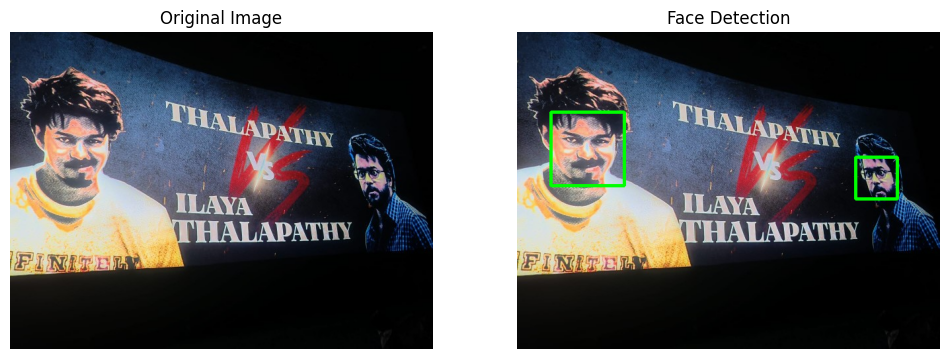

In [9]:
import cv2
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Face Detection")
plt.axis("off")

plt.show()